In [ ]:
%pip install -q pandas numpy matplotlib seaborn scikit-learn xgboost imbalanced-learn joblib streamlit plotly

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
import pickle
import plotly.express as px
from sklearn.preprocessing import MinMaxScaler

df=pd.read_csv('Customer-Churn-Records.csv')

In [2]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Card Type,Point Earned
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1,1,2,DIAMOND,464
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0,1,3,DIAMOND,456
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1,1,3,DIAMOND,377
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0,0,5,GOLD,350
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0,0,5,GOLD,425


In [3]:
df.describe()

,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Complain,Satisfaction Score,Point Earned
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203800,0.204400,3.013800,606.515100
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402842,0.403283,1.405919,225.924839
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000,0.000000,1.000000,119.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000,0.000000,2.000000,410.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000,0.000000,3.000000,605.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000,0.000000,4.000000,801.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000,1.000000,5.000000,1000.000000


In [4]:
print(df.columns.tolist())

['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited', 'Complain', 'Satisfaction Score', 'Card Type', 'Point Earned']


In [5]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 18 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   RowNumber           10000 non-null  int64  
 1   CustomerId          10000 non-null  int64  
 2   Surname             10000 non-null  object 
 3   CreditScore         10000 non-null  int64  
 4   Geography           10000 non-null  object 
 5   Gender              10000 non-null  object 
 6   Age                 10000 non-null  int64  
 7   Tenure              10000 non-null  int64  
 8   Balance             10000 non-null  float64
 9   NumOfProducts       10000 non-null  int64  
 10  HasCrCard           10000 non-null  int64  
 11  IsActiveMember      10000 non-null  int64  
 12  EstimatedSalary     10000 non-null  float64
 13  Exited              10000 non-null  int64  
 14  Complain            10000 non-null  int64  
 15  Satisfaction Score  10000 non-null  int64  
 16  Card 

In [2]:
df=df.drop(columns=['CustomerId','RowNumber','Complain'])

In [3]:
df.sample(5)

,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited,Satisfaction Score,Card Type,Point Earned
3635,Kelechi,740,France,Female,37,5,0.00,2,1,1,27528.40,0,5,PLATINUM,798
9268,Chukwuebuka,596,Spain,Male,29,2,0.00,2,1,1,1591.19,0,2,DIAMOND,224
775,McElroy,648,France,Male,33,7,134944.00,1,1,1,117036.38,0,2,PLATINUM,219
6854,Tomlinson,738,Spain,Male,36,5,0.00,2,1,1,96881.32,0,1,GOLD,856
1240,Septimus,579,France,Male,36,9,129829.59,1,1,1,60906.12,0,5,GOLD,725


In [4]:
col = df.pop('Exited')
df['Exited'] = col

In [9]:
df.head()

,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Satisfaction Score,Card Type,Point Earned,Exited
0,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,2,DIAMOND,464,1
1,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,3,DIAMOND,456,0
2,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,3,DIAMOND,377,1
3,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,5,GOLD,350,0
4,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,5,GOLD,425,0


In [5]:
#Unique features of each column
for column in df:
    unique_val=np.unique(df[column].fillna('0'))
    nr_values=len(unique_val)
    if nr_values <= 12:
       print('The number of values for feature {} :{} -- {}'.format(column, nr_values,unique_val))
    else:
       print('The number of values for feature {} :{}'.format(column, nr_values))
       


The number of values for feature Surname :2932
The number of values for feature CreditScore :460
The number of values for feature Geography :3 -- ['France' 'Germany' 'Spain']
The number of values for feature Gender :2 -- ['Female' 'Male']
The number of values for feature Age :70
The number of values for feature Tenure :11 -- [ 0  1  2  3  4  5  6  7  8  9 10]
The number of values for feature Balance :6382
The number of values for feature NumOfProducts :4 -- [1 2 3 4]
The number of values for feature HasCrCard :2 -- [0 1]
The number of values for feature IsActiveMember :2 -- [0 1]
The number of values for feature EstimatedSalary :9999
The number of values for feature Satisfaction Score :5 -- [1 2 3 4 5]
The number of values for feature Card Type :4 -- ['DIAMOND' 'GOLD' 'PLATINUM' 'SILVER']
The number of values for feature Point Earned :785
The number of values for feature Exited :2 -- [0 1]


In [11]:
df.shape

(10000, 15)

In [6]:
df.isnull().sum()

Surname               0
CreditScore           0
Geography             0
Gender                0
Age                   0
Tenure                0
Balance               0
NumOfProducts         0
HasCrCard             0
IsActiveMember        0
EstimatedSalary       0
Satisfaction Score    0
Card Type             0
Point Earned          0
Exited                0
dtype: int64

In [13]:
#This indicates that there is no missing data here

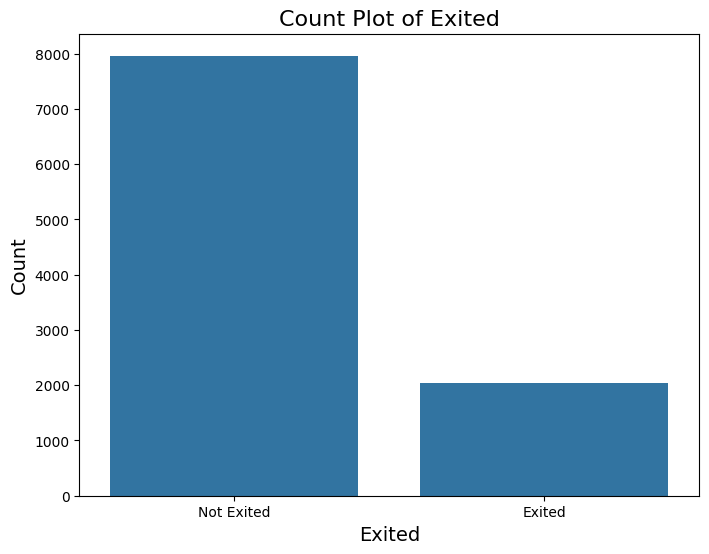

In [7]:
plt.figure(figsize=(8, 6))
sns.countplot(data=df, x="Exited")
plt.title("Count Plot of Exited", fontsize=16)
plt.xlabel("Exited", fontsize=14)
plt.ylabel("Count", fontsize=14)
plt.xticks([0, 1], labels=["Not Exited", "Exited"])
plt.show()

In [ ]:
df_new=df[['CreditScore','Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited']]
sns.pairplot(df_new, hue='Exited',palette='Set2')

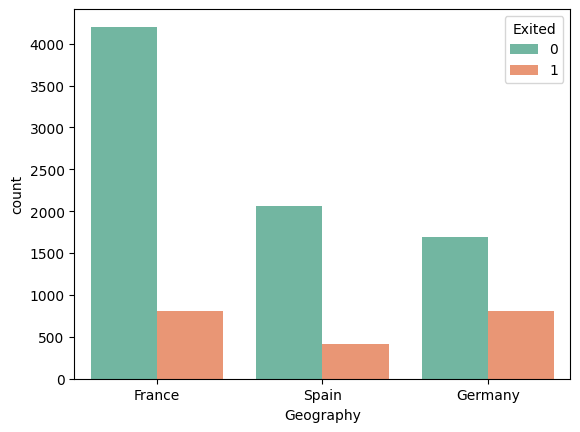

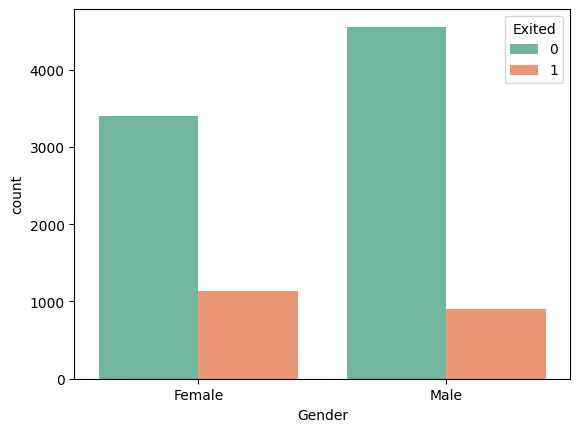

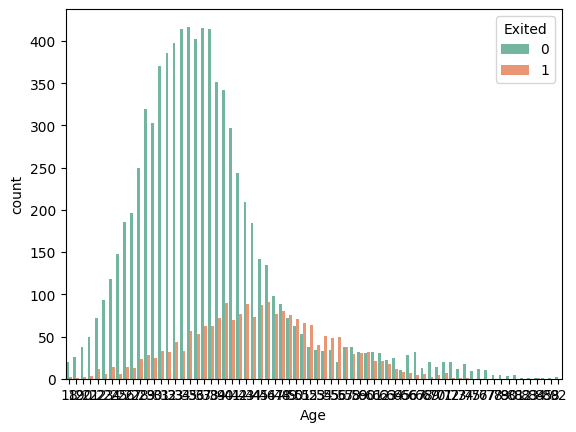

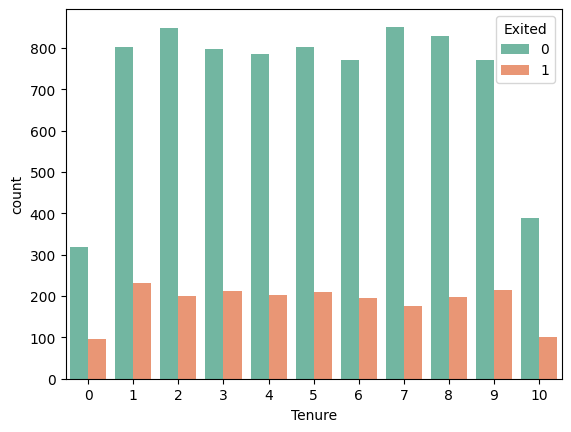

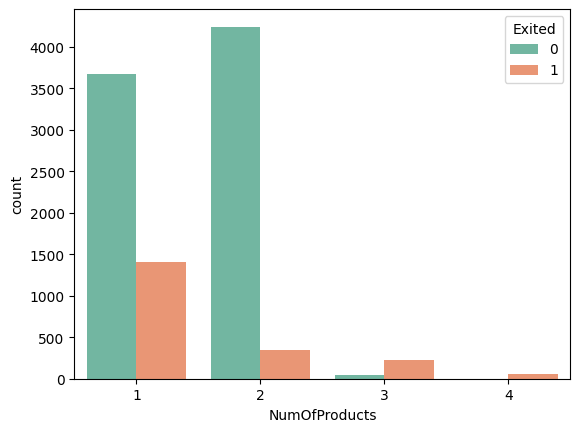

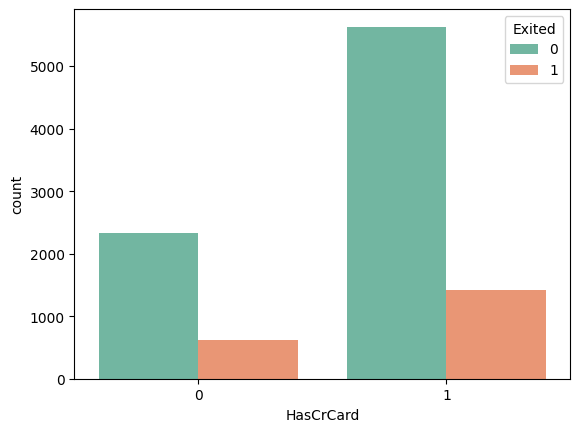

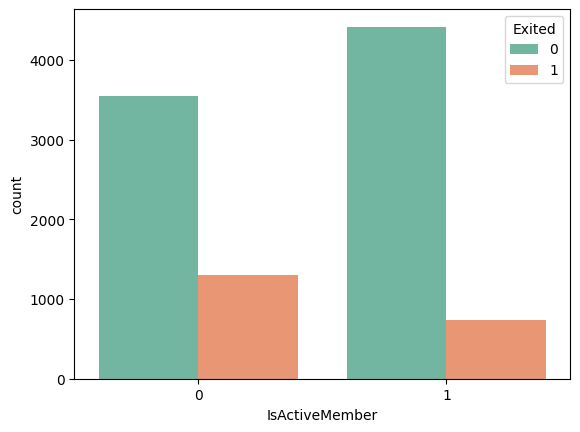

In [16]:
features=['Geography','Gender','Age','Tenure','NumOfProducts','HasCrCard', 'IsActiveMember']
for feature in features:
    plt.figure()
    ax=sns.countplot(x=feature, data=df, hue = 'Exited', palette="Set2")
    # plt.title(f'{feature} against Customer Churn')
    # plt.xlabel(feature)
    # plt.ylabel('Number of Consumers')
    # plt.xticks(rotation=45)
    # plt.legend(title='Exited', labels=['Stayed (0)', 'Churned (1)'])
    # plt.tight_layout()
    # plt.show()

The median is:  652.0


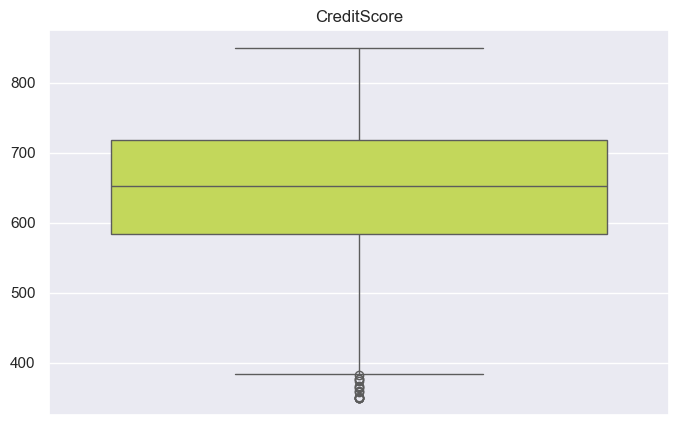

The median is:  37.0


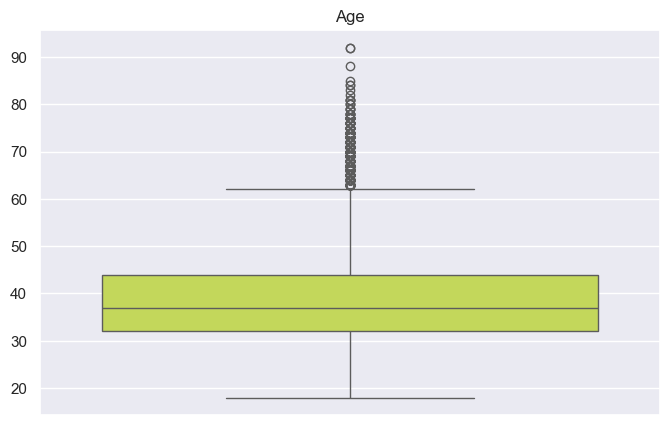

The median is:  5.0


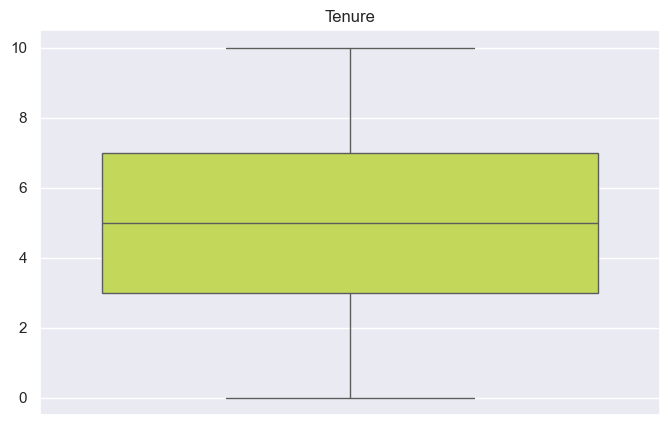

The median is:  97198.54000000001


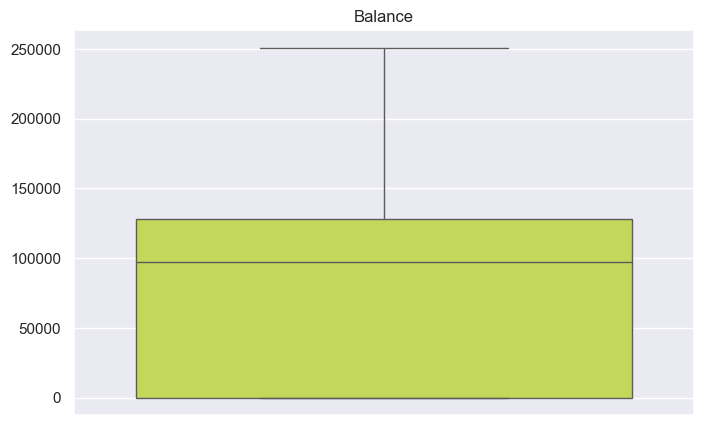

The median is:  1.0


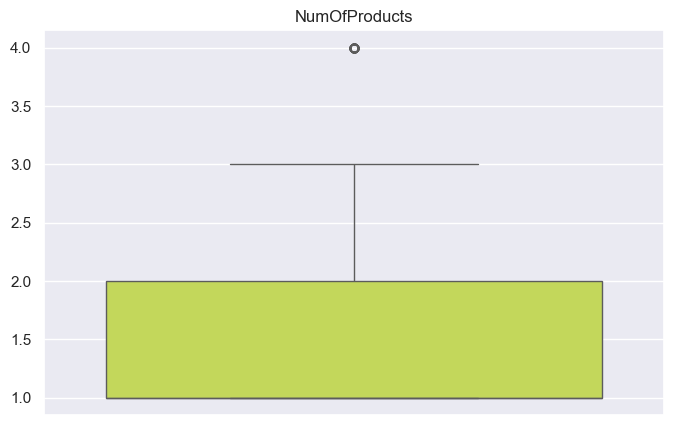

The median is:  1.0


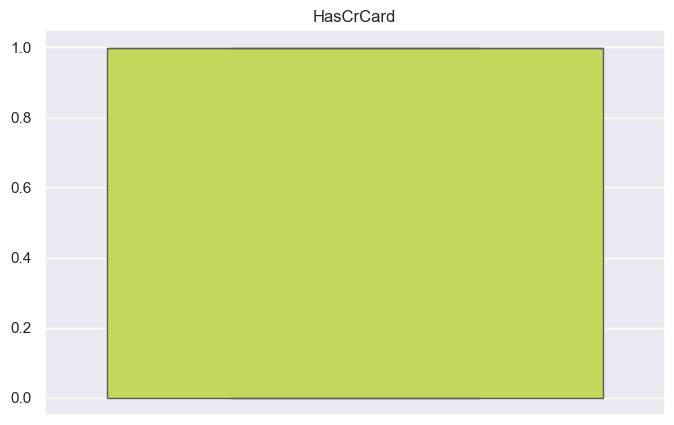

The median is:  1.0


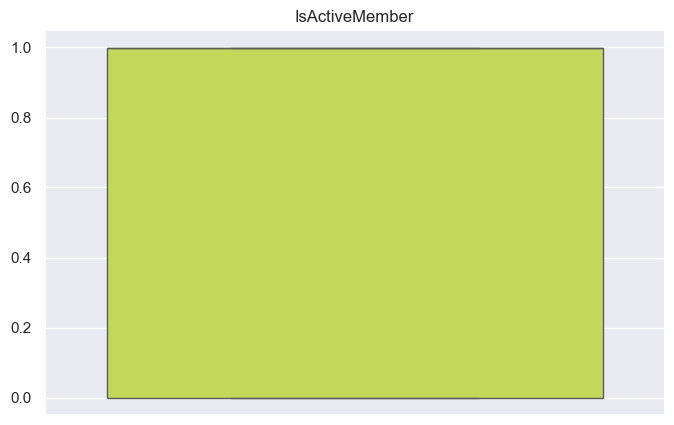

The median is:  100193.915


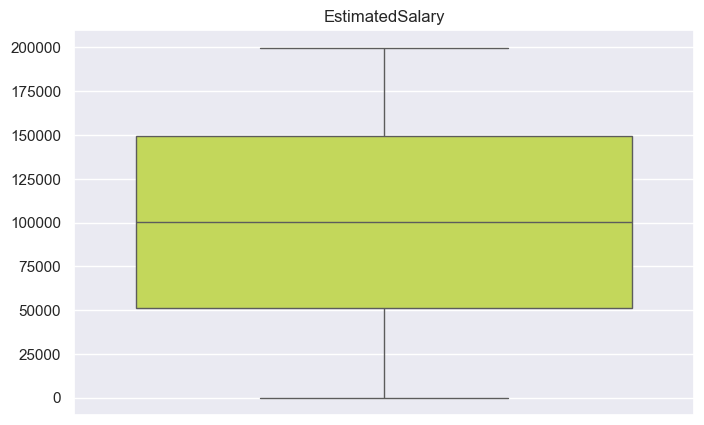

The median is:  3.0


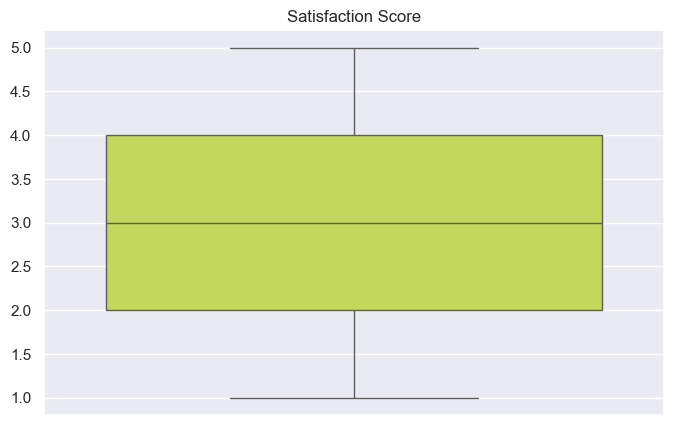

The median is:  605.0


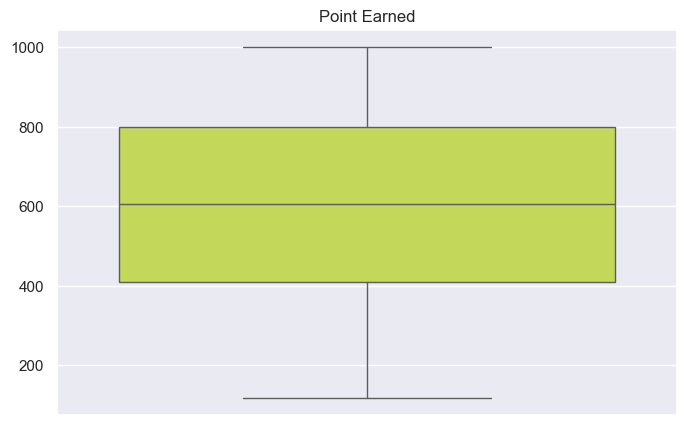

The median is:  0.0


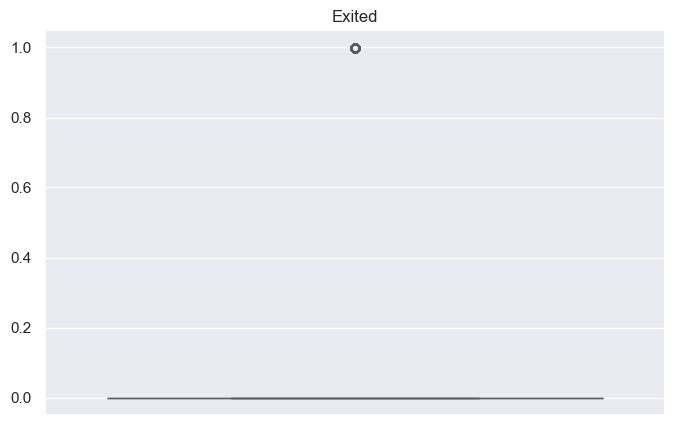

In [17]:
#Now we are going to boxplot to examine the anomalies or outliers sns set is used for setting the size of box plot here it is 8 in *5 in
numerical=['int16','int32','int64','float32','float64','float16']
variables=df.select_dtypes(include=numerical).columns
sns.set(rc={'figure.figsize':(8,5)})
for c in variables:    
    x = df[c].values
    ax = sns.boxplot(x, color = '#D1EC46')
    print('The median is: ', df[c].median())
    plt.title(c)
    plt.show()



In [18]:
df.head()

,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Satisfaction Score,Card Type,Point Earned,Exited
0,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,2,DIAMOND,464,1
1,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,3,DIAMOND,456,0
2,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,3,DIAMOND,377,1
3,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,5,GOLD,350,0
4,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,5,GOLD,425,0


In [12]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, MinMaxScaler
columns_to_remove = ['Surname', 'Exited', 'Complain', 'RowNumber', 'CustomerId']
X = df.drop(columns=columns_to_remove, errors='ignore')
y = df['Exited']
#Ye hum kar rhe before strating any scaling
X_train,X_test, y_train,y_test= train_test_split(X,y,test_size=0.25,random_state=42,stratify=y)
#Column tranformer
numeric_features = ['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'EstimatedSalary']
categorical_features = ['Geography', 'Gender','Card Type']
preprocessor=ColumnTransformer(
            transformers=[
                        ('num',MinMaxScaler(),numeric_features),
                        ('col', OneHotEncoder(drop='first',sparse_output=False, handle_unknown='ignore'), categorical_features)
            ],
           remainder='passthrough',
    verbose_feature_names_out=False
 )
X_train_processed=preprocessor.fit_transform(X_train)
X_test_processed=preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

X_train_final = pd.DataFrame(X_train_processed, columns=feature_names, index=X_train.index)
X_test_final = pd.DataFrame(X_test_processed, columns=feature_names, index=X_test.index)

print(f"X_train shape: {X_train_final.shape}")
print(f"X_test shape: {X_test_final.shape}")
X_train_final.head()

X_train shape: (7500, 16)
X_test shape: (2500, 16)


,CreditScore,Age,Tenure,Balance,NumOfProducts,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male,Card Type_GOLD,Card Type_PLATINUM,Card Type_SILVER,HasCrCard,IsActiveMember,Satisfaction Score,Point Earned
2251,0.654,0.094595,0.8,0.588778,0.000000,0.212013,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,5.0,236.0
1466,0.566,0.148649,0.7,0.764791,0.000000,0.021304,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,3.0,613.0
7579,0.502,0.297297,1.0,0.575198,0.000000,0.866253,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,376.0
3647,0.758,0.662162,0.2,0.423830,0.000000,0.511946,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,2.0,948.0
4202,0.352,0.162162,0.9,0.000000,0.333333,0.504969,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,518.0


In [13]:
#Baseline model training
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
baseline_model=LogisticRegression(class_weight={0: 1.0, 1: 2.2},max_iter=1000,random_state=42)
baseline_model.fit(X_train_final,y_train)
#now for the predictions
y_pred=baseline_model.predict(X_test_final)
y_proba = baseline_model.predict_proba(X_test_final)[:, 1]
print("Confusion matrix")
print(confusion_matrix(y_test,y_pred))
print("\n Classification Report")
print(classification_report(y_test,y_pred))
print(f"ROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}")

Confusion matrix
[[1750  241]
 [ 258  251]]

 Classification Report
              precision    recall  f1-score   support

           0       0.87      0.88      0.88      1991
           1       0.51      0.49      0.50       509

    accuracy                           0.80      2500
   macro avg       0.69      0.69      0.69      2500
weighted avg       0.80      0.80      0.80      2500

ROC-AUC Score: 0.7839


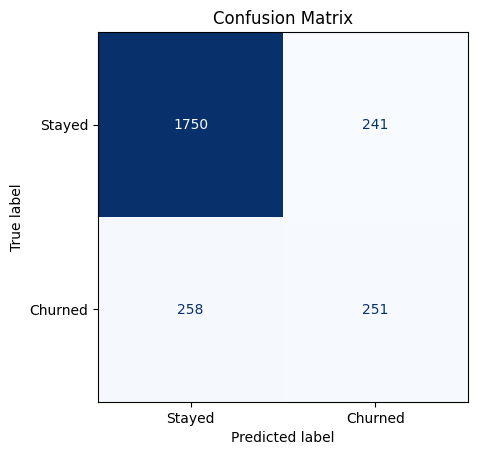

In [14]:
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=["Stayed", "Churned"],
    cmap="Blues", colorbar=False
)
plt.title("Confusion Matrix")
plt.show()

Our Baseline model is giving us almost 79% accuracy and the now we will use XGboost yo improve the accuracy

Chosen threshold: 0.179
 Confusion Matrix 
[[1547  444]
 [ 100  409]]

Classification Report 
              precision    recall  f1-score   support

      Stayed       0.94      0.78      0.85      1991
     Churned       0.48      0.80      0.60       509

    accuracy                           0.78      2500
   macro avg       0.71      0.79      0.73      2500
weighted avg       0.85      0.78      0.80      2500

XGBoost ROC-AUC: 0.8752


In [24]:
import numpy as np
from sklearn.metrics import classification_report, confusion_matrix

thresholds_to_try = np.arange(0.10, 0.91, 0.10)

for t in thresholds_to_try:
    preds = (xgb_probabilities >= t).astype(int)
    print(f"\n Threshold: {t:.2f} ")
    print(confusion_matrix(y_test, preds))
    print(classification_report(y_test, preds,
                                target_names=["Stayed", "Churned"], zero_division=0))


 Threshold: 0.10 
[[1183  808]
 [  45  464]]
              precision    recall  f1-score   support

      Stayed       0.96      0.59      0.74      1991
     Churned       0.36      0.91      0.52       509

    accuracy                           0.66      2500
   macro avg       0.66      0.75      0.63      2500
weighted avg       0.84      0.66      0.69      2500


 Threshold: 0.20 
[[1608  383]
 [ 119  390]]
              precision    recall  f1-score   support

      Stayed       0.93      0.81      0.86      1991
     Churned       0.50      0.77      0.61       509

    accuracy                           0.80      2500
   macro avg       0.72      0.79      0.74      2500
weighted avg       0.84      0.80      0.81      2500


 Threshold: 0.30 
[[1772  219]
 [ 175  334]]
              precision    recall  f1-score   support

      Stayed       0.91      0.89      0.90      1991
     Churned       0.60      0.66      0.63       509

    accuracy                           0.84 

In [19]:
import pandas as pd
from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score

rows = []
for t in np.arange(0.05, 0.96, 0.05):
    preds = (xgb_probabilities >= t).astype(int)
    rows.append({
        "threshold": round(t, 2),
        "precision": precision_score(y_test, preds, zero_division=0),
        "recall": recall_score(y_test, preds, zero_division=0),
        "f1": f1_score(y_test, preds, zero_division=0),
        "accuracy": accuracy_score(y_test, preds),
        "flagged": preds.sum()
    })

threshold_table = pd.DataFrame(rows).round(3)
print(threshold_table.to_string(index=False))

 threshold  precision  recall    f1  accuracy  flagged
      0.05      0.282   0.967 0.437     0.493     1742
      0.10      0.365   0.912 0.521     0.659     1272
      0.15      0.445   0.839 0.581     0.754      960
      0.20      0.505   0.766 0.608     0.799      773
      0.25      0.555   0.707 0.622     0.825      649
      0.30      0.604   0.656 0.629     0.842      553
      0.35      0.657   0.613 0.634     0.856      475
      0.40      0.695   0.578 0.631     0.862      423
      0.45      0.731   0.538 0.620     0.866      375
      0.50      0.757   0.495 0.599     0.865      333
      0.55      0.807   0.460 0.586     0.868      290
      0.60      0.849   0.418 0.561     0.866      251
      0.65      0.889   0.377 0.530     0.864      216
      0.70      0.921   0.344 0.501     0.860      190
      0.75      0.944   0.297 0.451     0.853      160
      0.80      0.949   0.253 0.400     0.845      136
      0.85      0.961   0.193 0.321     0.834      102
      0.90

In [20]:
import numpy as np
import pandas as pd
from sklearn.model_selection import cross_val_predict, StratifiedKFold
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_auc_score)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

cv_probs = cross_val_predict(xgb_model, X_train, y_train, cv=skf,
                             method="predict_proba", n_jobs=-1)[:, 1]

rows = []
for t in np.arange(0.05, 0.96, 0.05):
    preds = (cv_probs >= t).astype(int)
    rows.append({
        "threshold": round(t, 2),
        "precision": precision_score(y_train, preds, zero_division=0),
        "recall": recall_score(y_train, preds, zero_division=0),
        "f1": f1_score(y_train, preds, zero_division=0),
        "flagged": preds.sum()
    })

cv_table = pd.DataFrame(rows).round(3)
print(cv_table.to_string(index=False))

best_threshold = cv_table.loc[cv_table["f1"].idxmax(), "threshold"]
print(f"\nCV-selected threshold: {best_threshold}")

xgb_model.fit(X_train, y_train)
test_probs = xgb_model.predict_proba(X_test)[:, 1]
final_preds = (test_probs >= best_threshold).astype(int)

print("\nConfusion Matrix")
print(confusion_matrix(y_test, final_preds))
print("\nClassification Report")
print(classification_report(y_test, final_preds,
                            target_names=["Stayed", "Churned"], zero_division=0))
print(f"XGBoost ROC-AUC: {roc_auc_score(y_test, test_probs):.4f}")

 threshold  precision  recall    f1  flagged
      0.05      0.283   0.956 0.437     5160
      0.10      0.368   0.877 0.519     3642
      0.15      0.437   0.810 0.568     2834
      0.20      0.504   0.750 0.602     2276
      0.25      0.553   0.690 0.614     1908
      0.30      0.601   0.646 0.623     1645
      0.35      0.640   0.592 0.615     1413
      0.40      0.685   0.546 0.608     1219
      0.45      0.714   0.502 0.589     1074
      0.50      0.755   0.468 0.578      948
      0.55      0.790   0.434 0.560      839
      0.60      0.812   0.398 0.534      750
      0.65      0.847   0.365 0.510      659
      0.70      0.880   0.330 0.480      573
      0.75      0.899   0.298 0.447      506
      0.80      0.920   0.257 0.402      427
      0.85      0.946   0.205 0.337      332
      0.90      0.952   0.144 0.250      231
      0.95      0.969   0.082 0.152      130

CV-selected threshold: 0.3

Confusion Matrix
[[1772  219]
 [ 175  334]]

Classification Report
    

The difference between Baseline Model and XGBoost

In [23]:
for t in [0.30, 0.35]:
    p = (test_probs >= t).astype(int)
    print(f"\n Threshold--> {t} ")
    print(confusion_matrix(y_test, p))
    print(classification_report(y_test, p,
                                target_names=["Stayed", "Churned"], zero_division=0))


 Threshold--> 0.3 
[[1772  219]
 [ 175  334]]
              precision    recall  f1-score   support

      Stayed       0.91      0.89      0.90      1991
     Churned       0.60      0.66      0.63       509

    accuracy                           0.84      2500
   macro avg       0.76      0.77      0.76      2500
weighted avg       0.85      0.84      0.84      2500


 Threshold--> 0.35 
[[1828  163]
 [ 197  312]]
              precision    recall  f1-score   support

      Stayed       0.90      0.92      0.91      1991
     Churned       0.66      0.61      0.63       509

    accuracy                           0.86      2500
   macro avg       0.78      0.77      0.77      2500
weighted avg       0.85      0.86      0.85      2500



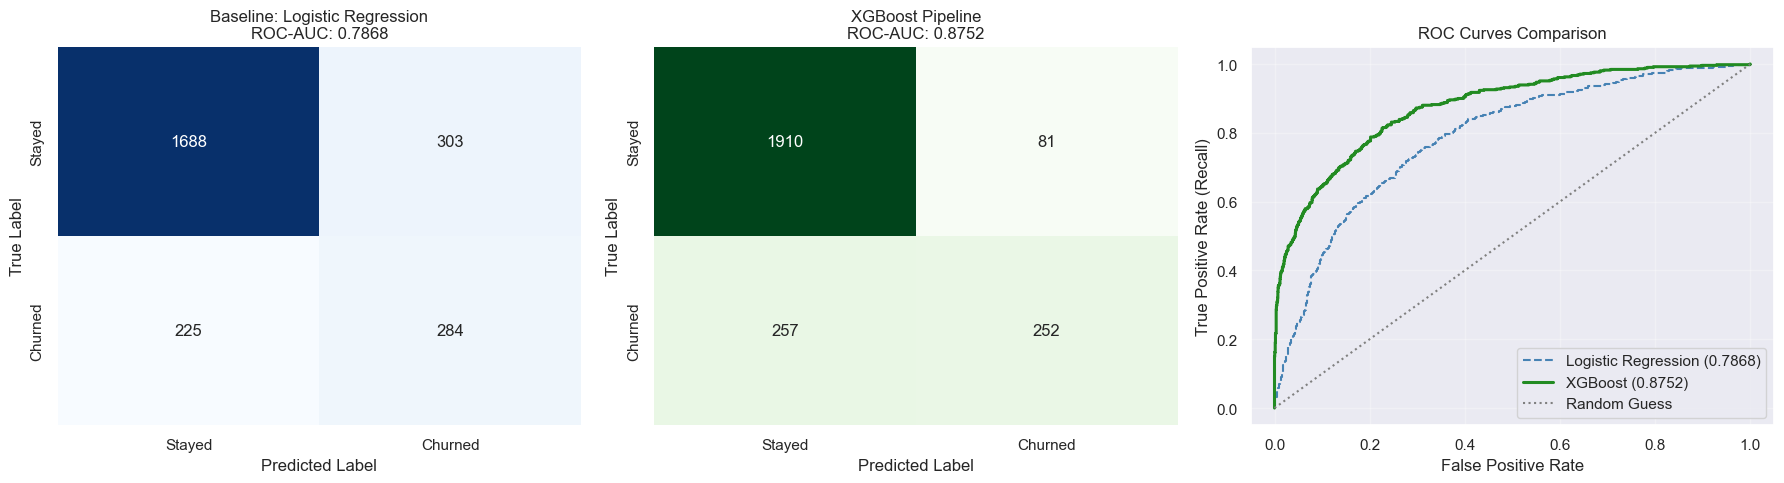

Model saved successfully as: customer_churn_xgb_pipeline.pkl

Sample verification output:
Predicted classes: [0 1 0]
Churn probabilities: [0.1335 0.5544 0.0326]


In [33]:
import joblib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# Plot 1: Baseline (Logistic Regression) Confusion Matrix
cm_lr = confusion_matrix(y_test, y_pred)
sns.heatmap(cm_lr, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title(f"Baseline: Logistic Regression\nROC-AUC: {roc_auc_score(y_test, y_proba):.4f}")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("True Label")
axes[0].set_xticklabels(['Stayed', 'Churned'])
axes[0].set_yticklabels(['Stayed', 'Churned'])
cm_xgb = confusion_matrix(y_test, xgb_predictions)
sns.heatmap(cm_xgb, annot=True, fmt='d', cmap='Greens', ax=axes[1], cbar=False)
axes[1].set_title(f"XGBoost Pipeline\nROC-AUC: {roc_auc_score(y_test, xgb_probabilities):.4f}")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("True Label")
axes[1].set_xticklabels(['Stayed', 'Churned'])
axes[1].set_yticklabels(['Stayed', 'Churned'])
# Plot 3: Side-by-Side ROC Curves
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_probabilities)
axes[2].plot(fpr_lr, tpr_lr, label=f"Logistic Regression ({roc_auc_score(y_test, y_proba):.4f})", color='steelblue', linestyle='--')
axes[2].plot(fpr_xgb, tpr_xgb, label=f"XGBoost ({roc_auc_score(y_test, xgb_probabilities):.4f})", color='forestgreen', linewidth=2.2)
axes[2].plot([0, 1], [0, 1], color='gray', linestyle=':', label='Random Guess')
axes[2].set_title("ROC Curves Comparison")
axes[2].set_xlabel("False Positive Rate")
axes[2].set_ylabel("True Positive Rate (Recall)")
axes[2].legend(loc="lower right")
axes[2].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()
pkl_filename = "customer_churn_xgb_pipeline.pkl"
joblib.dump(xgb_model, pkl_filename)
print(f"Model saved successfully as: {pkl_filename}")
loaded_pipeline = joblib.load(pkl_filename)
test_sample = X_test.iloc[:3]
print("\nSample verification output:")
print("Predicted classes:", loaded_pipeline.predict(test_sample))
print("Churn probabilities:", loaded_pipeline.predict_proba(test_sample)[:, 1].round(4))